# Atelier 2 — Partie 1 : CNN, Faster R-CNN et transfert

**Auteur : KARMAS Hammam**

Ce notebook explique et exécute les quatre modèles de la première partie.
Les sorties enregistrées dans le dépôt proviennent d'une vérification **CPU smoke**.
Dans Colab, sélectionner **Exécution → Modifier le type d'exécution → GPU**, puis
**Tout exécuter** : le profil complet GPU est sélectionné automatiquement.

La première exécution télécharge MNIST et les poids officiels (environ 1 Go pour
les trois modèles préentraînés). Les entraînements complets peuvent être longs,
particulièrement VGG16 et Faster R-CNN. Les résultats terminés sont réutilisés si
leur configuration, leur code et leurs partitions sont identiques.

In [1]:
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

# Local : reconnaître la racine du dépôt ou son dossier notebooks/.
ROOT = Path.cwd()
if not (ROOT / 'src' / 'models.py').exists() and (ROOT.parent / 'src' / 'models.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'models.py').exists():
    # Colab : le notebook ouvert depuis GitHub ne clone pas les autres fichiers.
    ROOT = Path('/content/Atelier2_DeepLearning')
    if not ROOT.exists():
        subprocess.run(['git', 'clone', 'https://github.com/KarmasHammam/Atelier2_DeepLearning.git', str(ROOT)], check=True)
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# Conserver le PyTorch CUDA fourni par Colab ; ne jamais installer une roue CPU ici.
if importlib.util.find_spec('google') and importlib.util.find_spec('google.colab'):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements-colab.txt'])

import json
import pandas as pd
import torch
import torchvision
from IPython.display import display, Image
from src.config import configuration
from src.train import run
from src.explore import explore
from src.compare import compare

PROFILE = 'full' if torch.cuda.is_available() else 'smoke'
DEVICE = 'cuda' if PROFILE == 'full' else 'cpu'
print('PyTorch :', torch.__version__, '| torchvision :', torchvision.__version__)
print('Profil :', PROFILE, '| Matériel :', torch.cuda.get_device_name(0) if PROFILE == 'full' else 'CPU')
if PROFILE == 'smoke':
    print('ATTENTION : vérification CPU sur 64 images de train, 40 de validation, 80 de test, une époque.')
    print('Les scores affichés NE SONT PAS les résultats finaux GPU demandés par le sujet.')
else:
    # Vérifier les opérations de détection CUDA avant un long entraînement.
    torchvision.ops.nms(torch.tensor([[0., 0., 2., 2.]], device='cuda'),
                        torch.tensor([.9], device='cuda'), .5)
    print('Expérience complète : 54 000 train, 6 000 validation, 10 000 test.')


def show_result(result):
    folder = ROOT / 'results' / PROFILE / result['model']
    print(result['model'], '|', result['purpose'])
    display(pd.DataFrame([{
        'accuracy test': result['test']['accuracy'], 'F1 macro test': result['test']['f1_macro'],
        'loss propre au modèle': result['test']['loss'],
        'temps train (s)': result['training_seconds'], 'époque choisie sur validation': result['selected_epoch'],
        'paramètres entraînables': result['trainable_parameters'],
    }]))
    display(Image(filename=str(folder / 'learning_curves.png')))
    display(Image(filename=str(folder / 'confusion_matrix.png')))
    display(pd.read_csv(folder / 'classification_report.csv', index_col=0))

PyTorch : 2.14.1+cpu | torchvision : 0.29.2+cpu
Profil : smoke | Matériel : CPU
ATTENTION : vérification CPU sur 64 images de train, 40 de validation, 80 de test, une époque.
Les scores affichés NE SONT PAS les résultats finaux GPU demandés par le sujet.


## Comprendre les données et le protocole commun

MNIST contient 60 000 images d'apprentissage et 10 000 images de test, en niveaux
 de gris, de taille 28×28. Le train officiel est séparé en **54 000 train et 6 000
validation**, de manière stratifiée, avec la graine 42. Les cinq modèles utilisent
les mêmes indices. Le test officiel reste réservé à l'évaluation finale.

Le miroir GitHub fournit les fichiers IDX MNIST standard. Les empreintes MD5
attendues par torchvision sont conservées ; le téléchargement ne dépend pas d'une
clé Kaggle. La source demandée par le sujet reste indiquée dans le README.

L'augmentation géométrique du profil complet agit uniquement sur le train :
rotation jusqu'à 10° et translation jusqu'à 5 %. Les sondes de train, la validation
et le test ne sont pas augmentés. Les statistiques de normalisation sont des
constantes MNIST/ImageNet fixées, pas des valeurs estimées sur le test.

EDA enregistrée dans results/eda/.


,train,validation,test
chiffre,,,
0,5331,592,980
1,6068,674,1135
2,5362,596,1032
3,5518,613,1010
4,5258,584,982
5,4879,542,892
6,5326,592,958
7,5638,627,1028
8,5266,585,974


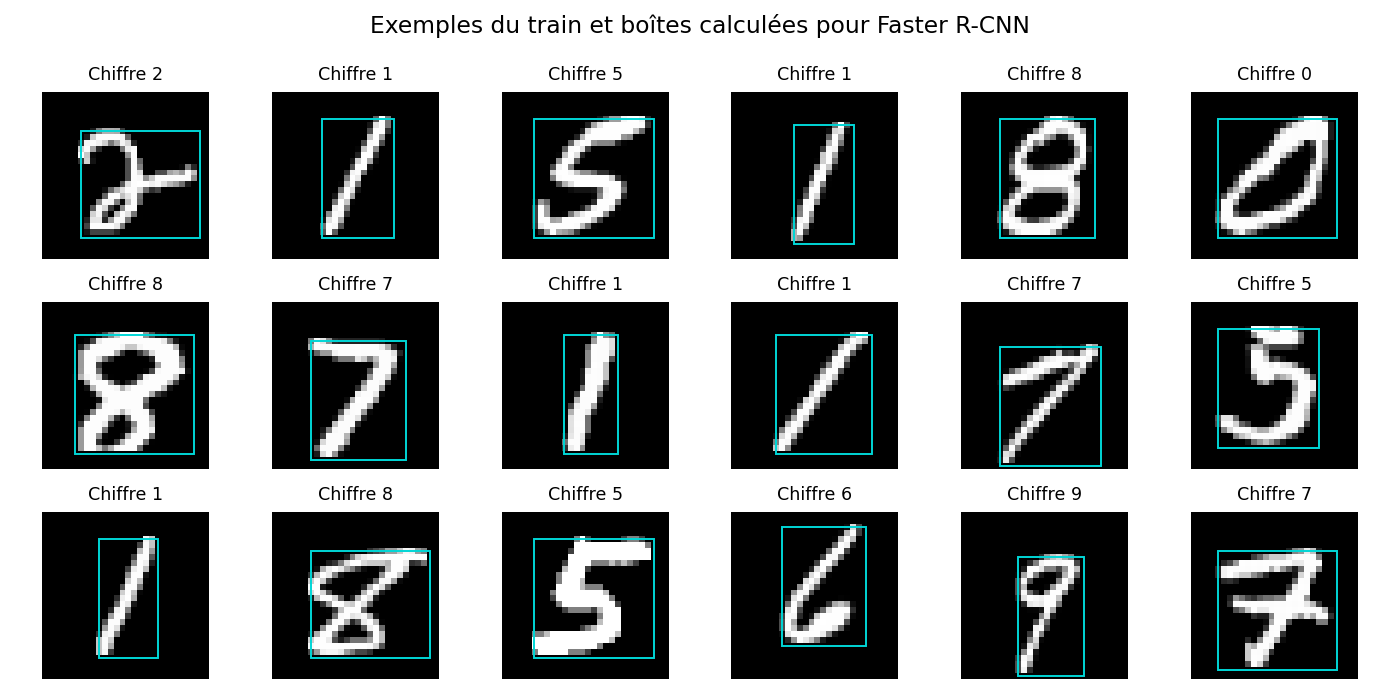

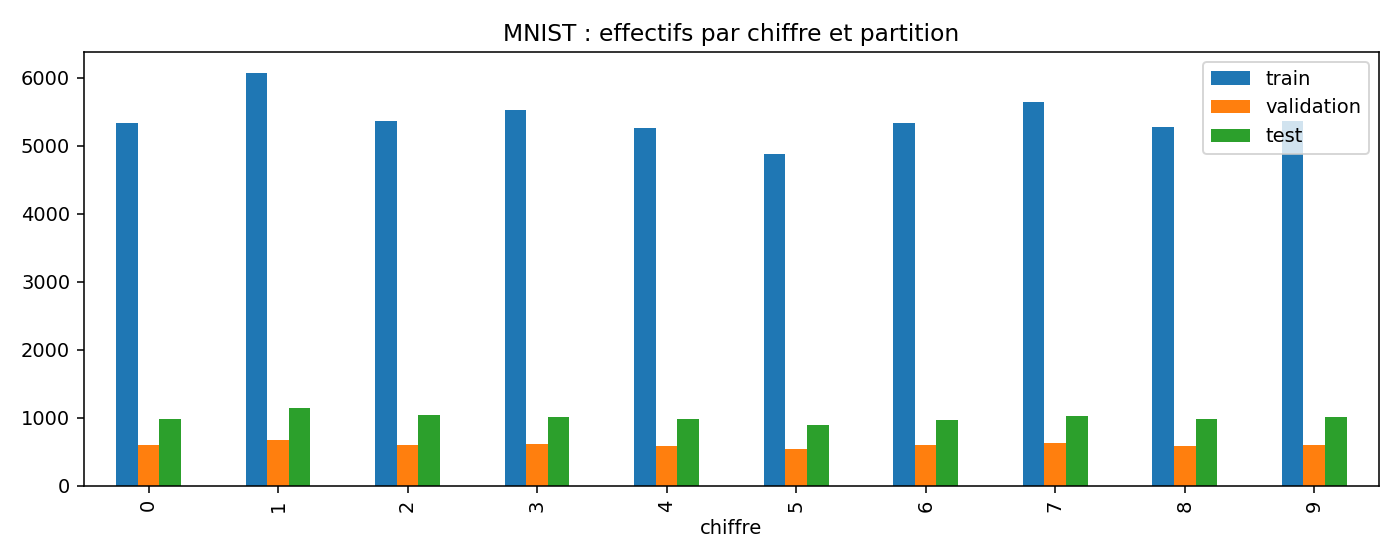

In [2]:
explore()
display(pd.read_csv(ROOT / 'results/eda/class_counts.csv', index_col=0))
display(Image(filename=str(ROOT / 'results/eda/examples_boxes.png')))
display(Image(filename=str(ROOT / 'results/eda/class_counts.png')))

## 1. Construire et entraîner le CNN

Une convolution apprend des motifs locaux : traits, courbes ou intersections.
Le noyau 3×3, le padding 1 et le stride 1 conservent la taille spatiale. Chaque
max-pooling 2×2 divise la résolution par deux : 28→14→7.

Architecture : Conv(1,32) → ReLU → Pool → Conv(32,64) → ReLU → Pool →
Linear(3136,128) → ReLU → Dropout(0,25) → Linear(128,10).
La sortie est un ensemble de dix logits, transmis directement à CrossEntropyLoss.
L'optimiseur est AdamW, avec un taux initial de 0,001 et une pénalité de 0,0001.

CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

Config(model='cnn', profile='smoke', seed=42, epochs=1, batch_size=4, lr=0.001, weight_decay=0.0001, train_size=64, valid_size=40, test_size=80, probe_size=40, augmentation=False, pretrained=False)
cnn : résultat existant réutilisé (smoke).


cnn | CPU functional smoke check, NOT final GPU evidence


,accuracy test,F1 macro test,loss propre au modèle,temps train (s),époque choisie sur validation,paramètres entraînables
0,0.3625,0.276415,2.246681,0.129991,1,421642


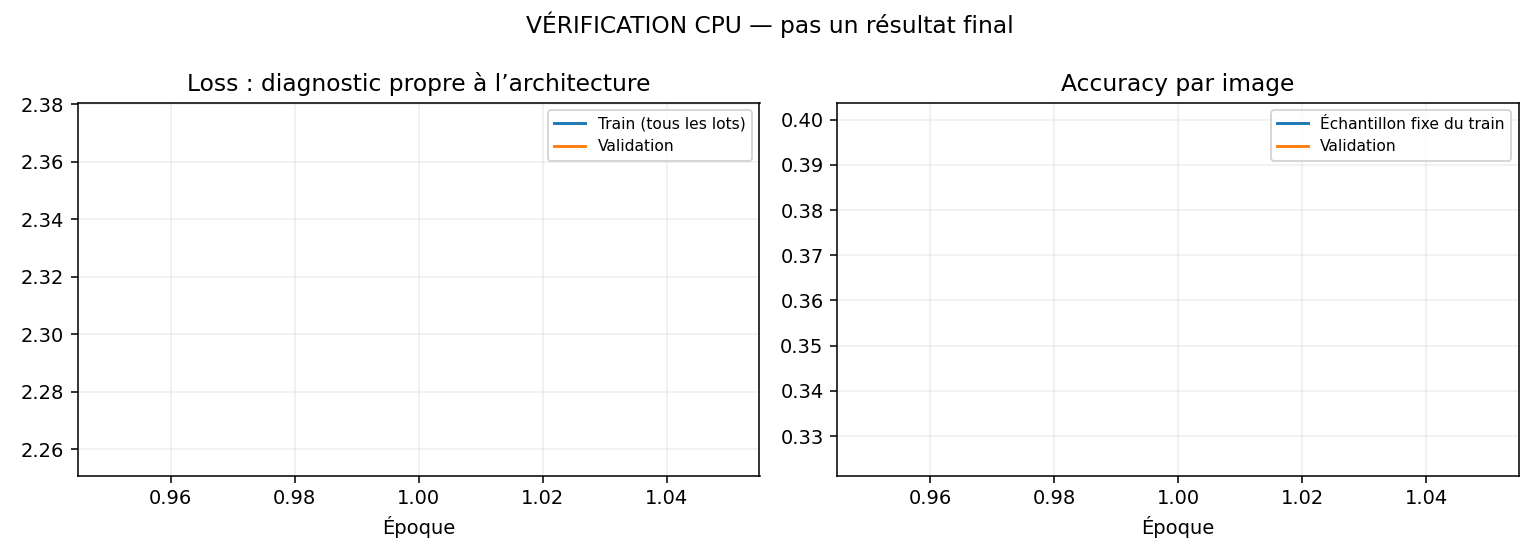

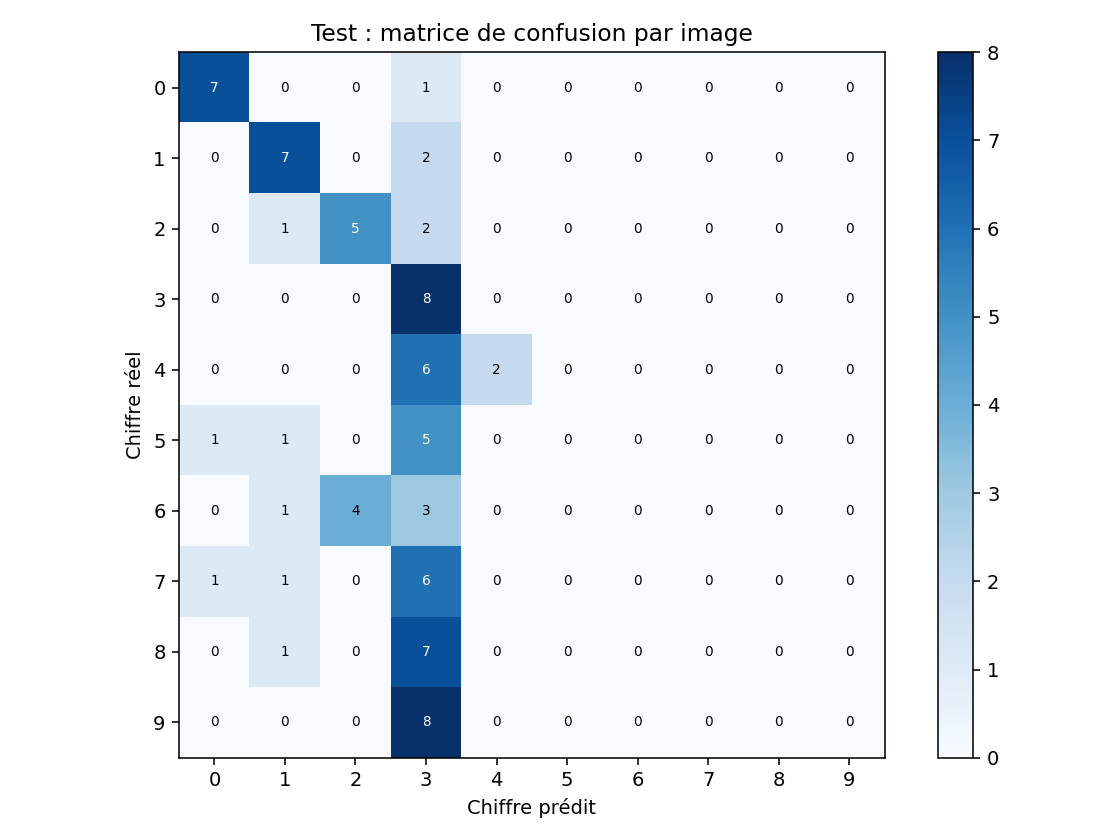

,precision,recall,f1-score,support
0,0.777778,0.875000,0.823529,8.0000
1,0.583333,0.777778,0.666667,9.0000
2,0.555556,0.625000,0.588235,8.0000
3,0.166667,1.000000,0.285714,8.0000
4,1.000000,0.250000,0.400000,8.0000
5,0.000000,0.000000,0.000000,7.0000
6,0.000000,0.000000,0.000000,8.0000
7,0.000000,0.000000,0.000000,8.0000
8,0.000000,0.000000,0.000000,8.0000
9,0.000000,0.000000,0.000000,8.0000


In [3]:
from src.models import CNN
display(CNN())
print(configuration('cnn', PROFILE))
cnn_result = run('cnn', profile=PROFILE, device_name=DEVICE)
show_result(cnn_result)

## 2. Adapter Faster R-CNN à MNIST

Faster R-CNN détecte des objets : le backbone ResNet50/FPN extrait des cartes,
le RPN propose des régions, puis la tête RoI prédit une boîte et sa classe.
MNIST ne fournit pas de boîtes. Nous encadrons donc tous les pixels non nuls de
chaque chiffre ; après augmentation, la boîte est recalculée.

Les images deviennent RGB et le détecteur les redimensionne à 64×64. Les ancres
sont adaptées aux petits chiffres. Le modèle utilise des poids COCO officiels,
puis sa tête est remplacée : **11 classes = fond + dix chiffres**. Le chiffre zéro
est encodé par 1 pendant la détection ; le fond reste 0.

Pour la comparaison par image, nous retenons la détection la plus confiante et
reconvertissons son étiquette en chiffre. Aucune détection donne -1 et compte
comme une erreur. Nous conservons aussi l'IoU de la boîte et le taux de réussite
« classe correcte et IoU ≥ 0,5 ». Ce protocole n'est pas une mesure mAP.

Config(model='fasterrcnn', profile='smoke', seed=42, epochs=1, batch_size=2, lr=0.005, weight_decay=0.0001, train_size=64, valid_size=40, test_size=80, probe_size=40, augmentation=False, pretrained=True)


fasterrcnn : résultat existant réutilisé (smoke).


fasterrcnn | CPU functional smoke check, NOT final GPU evidence


,accuracy test,F1 macro test,loss propre au modèle,temps train (s),époque choisie sur validation,paramètres entraînables
0,0.2625,0.167564,0.283803,26.009766,1,41122886


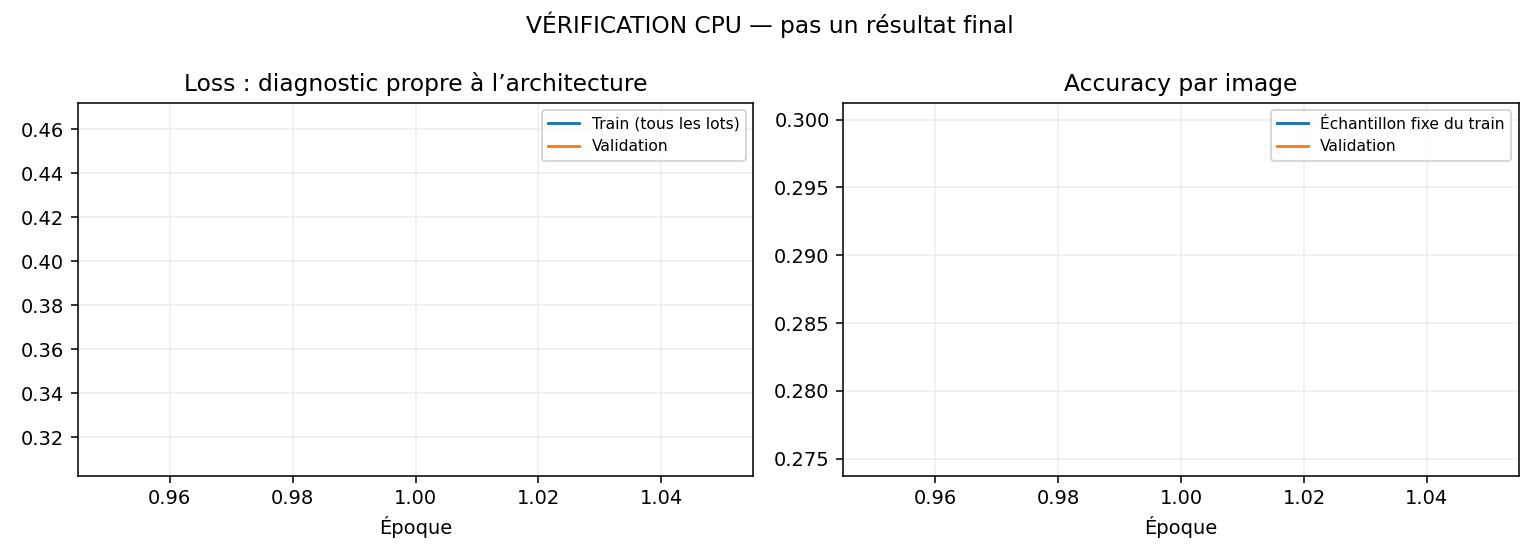

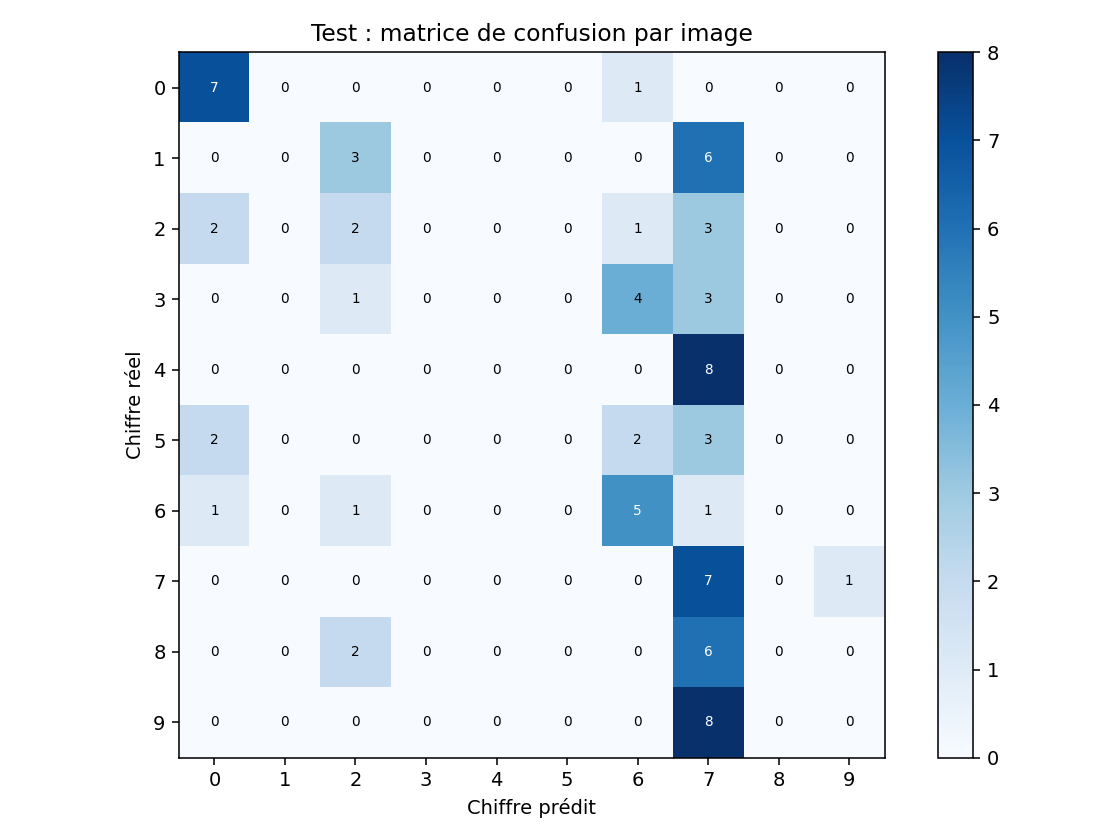

,precision,recall,f1-score,support
0,0.583333,0.8750,0.700000,8.0000
1,0.000000,0.0000,0.000000,9.0000
2,0.222222,0.2500,0.235294,8.0000
3,0.000000,0.0000,0.000000,8.0000
4,0.000000,0.0000,0.000000,8.0000
5,0.000000,0.0000,0.000000,7.0000
6,0.384615,0.6250,0.476190,8.0000
7,0.155556,0.8750,0.264151,8.0000
8,0.000000,0.0000,0.000000,8.0000
9,0.000000,0.0000,0.000000,8.0000


,no_detection_rate,mean_iou,label_and_iou50_accuracy
0,0.0,0.656779,0.2625


In [4]:
print(configuration('fasterrcnn', PROFILE))
faster_result = run('fasterrcnn', profile=PROFILE, device_name=DEVICE)
show_result(faster_result)
display(pd.DataFrame([{key: faster_result['test'][key] for key in
                      ['no_detection_rate', 'mean_iou', 'label_and_iou50_accuracy']}]))

## 3. Fine-tuning de VGG16

Les filtres ImageNet constituent un point de départ. Les images sont redimensionnées
à 224×224, répétées sur trois canaux et normalisées avec les constantes ImageNet.
Nous remplaçons la dernière couche par dix sorties. Le dernier bloc convolutif
et cette nouvelle tête sont entraînés ; les autres poids restent figés.
Il s'agit donc d'un fine-tuning partiel, et pas seulement d'une tête entraînée.
Le taux d'apprentissage est plus petit : 0,0001.

Config(model='vgg16', profile='smoke', seed=42, epochs=1, batch_size=4, lr=0.0001, weight_decay=0.0001, train_size=64, valid_size=40, test_size=80, probe_size=40, augmentation=False, pretrained=True)


vgg16 : résultat existant réutilisé (smoke).


vgg16 | CPU functional smoke check, NOT final GPU evidence


,accuracy test,F1 macro test,loss propre au modèle,temps train (s),époque choisie sur validation,paramètres entraînables
0,0.2625,0.215854,2.160725,14.000007,1,7120394


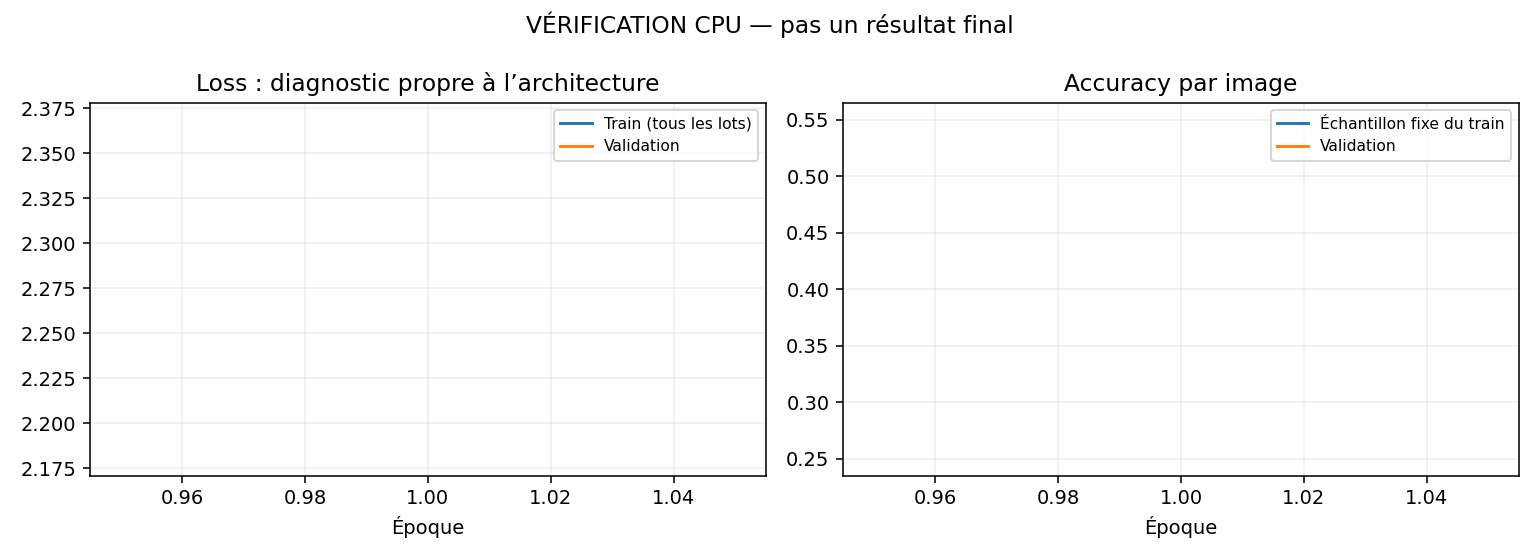

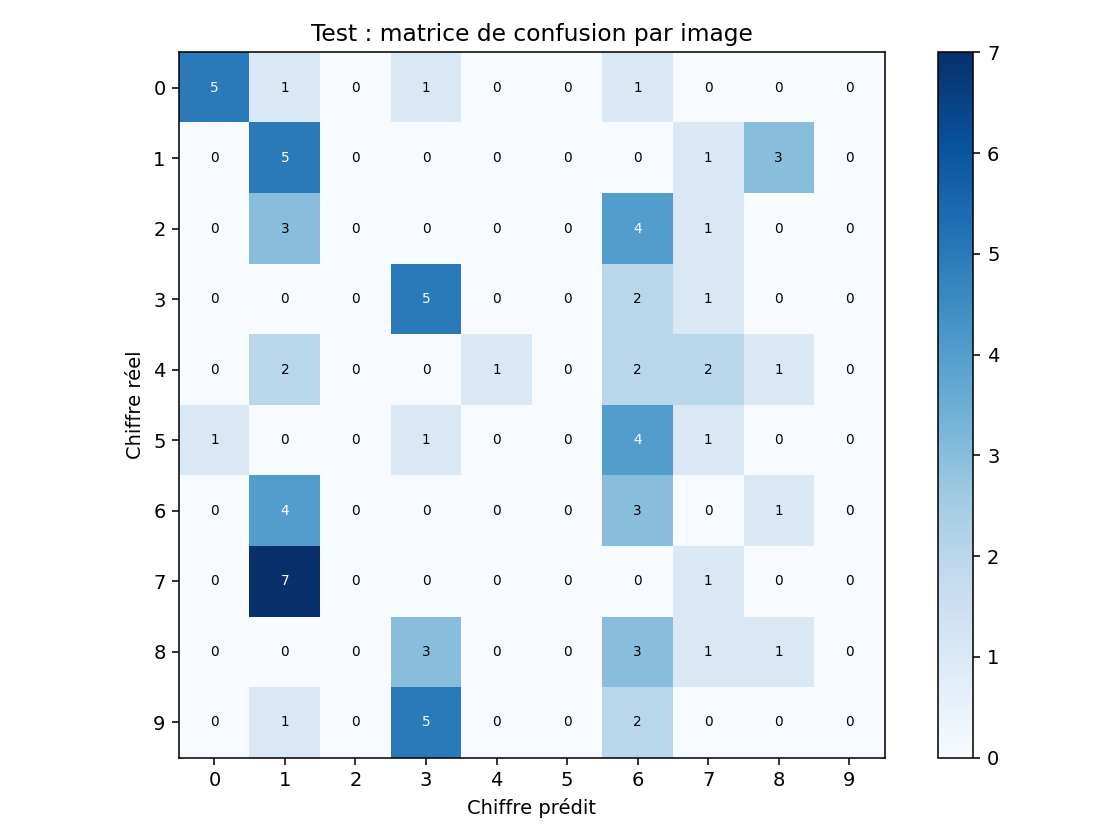

,precision,recall,f1-score,support
0,0.833333,0.625000,0.714286,8.0000
1,0.217391,0.555556,0.312500,9.0000
2,0.000000,0.000000,0.000000,8.0000
3,0.333333,0.625000,0.434783,8.0000
4,1.000000,0.125000,0.222222,8.0000
5,0.000000,0.000000,0.000000,7.0000
6,0.142857,0.375000,0.206897,8.0000
7,0.125000,0.125000,0.125000,8.0000
8,0.166667,0.125000,0.142857,8.0000
9,0.000000,0.000000,0.000000,8.0000


In [5]:
print(configuration('vgg16', PROFILE))
vgg_result = run('vgg16', profile=PROFILE, device_name=DEVICE)
show_result(vgg_result)

## 4. Fine-tuning d'AlexNet

La préparation des images est identique à VGG16. Le dernier bloc convolutif et
la tête à dix sorties sont ajustés. AlexNet et VGG16 disposent de poids ImageNet
préentraînés, alors que le CNN et le ViT partent de poids aléatoires : cette
connaissance préalable doit être mentionnée lors de l'interprétation.

Config(model='alexnet', profile='smoke', seed=42, epochs=1, batch_size=4, lr=0.0001, weight_decay=0.0001, train_size=64, valid_size=40, test_size=80, probe_size=40, augmentation=False, pretrained=True)


alexnet : résultat existant réutilisé (smoke).


alexnet | CPU functional smoke check, NOT final GPU evidence


,accuracy test,F1 macro test,loss propre au modèle,temps train (s),époque choisie sur validation,paramètres entraînables
0,0.275,0.227718,2.126278,1.066578,1,631050


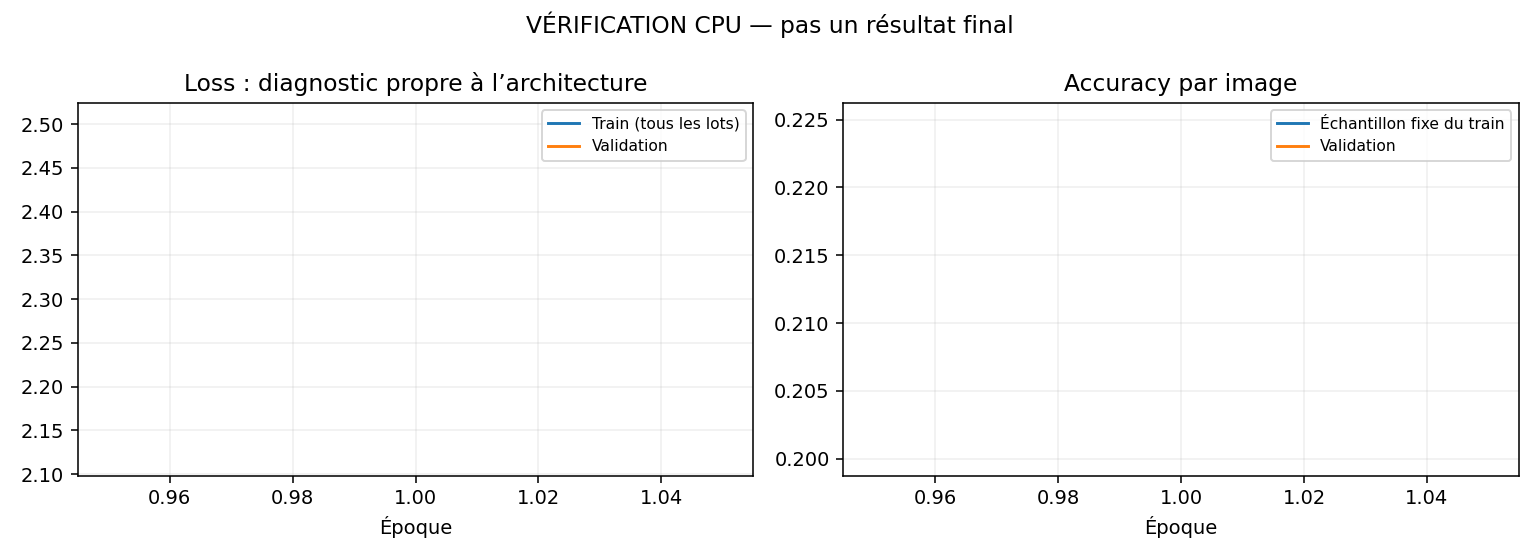

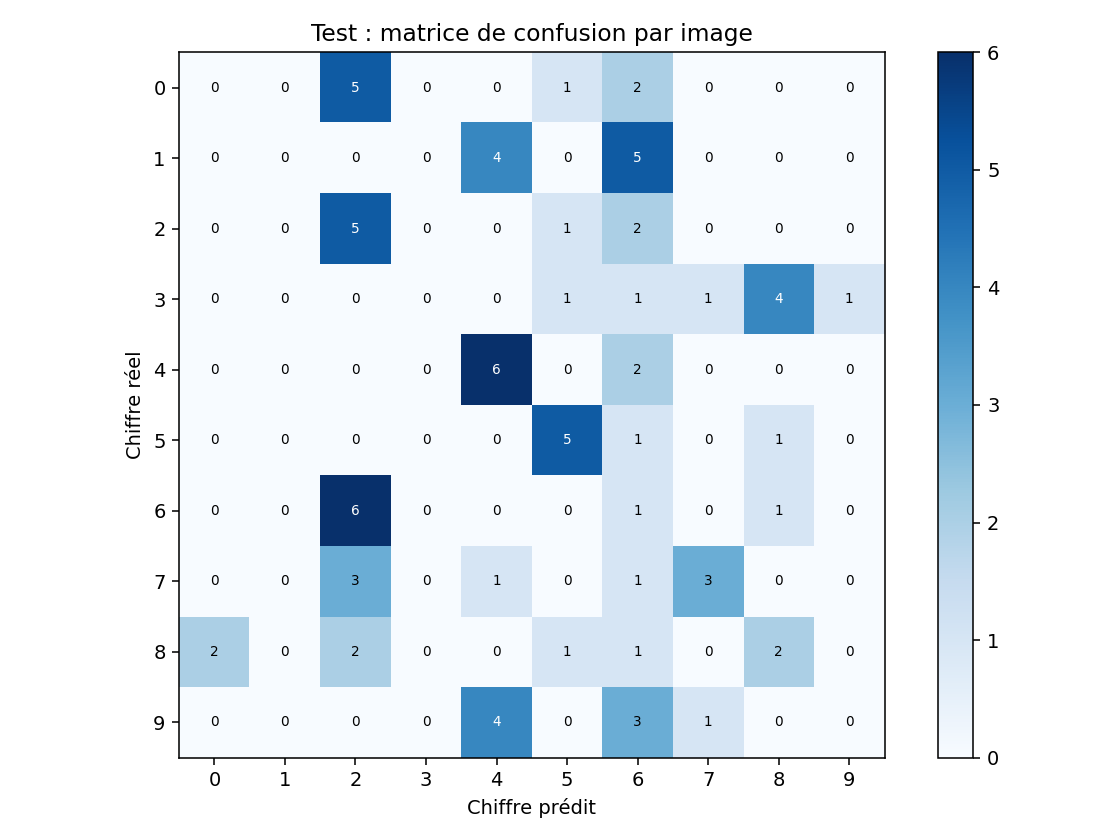

,precision,recall,f1-score,support
0,0.000000,0.000000,0.000000,8.000
1,0.000000,0.000000,0.000000,9.000
2,0.238095,0.625000,0.344828,8.000
3,0.000000,0.000000,0.000000,8.000
4,0.400000,0.750000,0.521739,8.000
5,0.555556,0.714286,0.625000,7.000
6,0.052632,0.125000,0.074074,8.000
7,0.600000,0.375000,0.461538,8.000
8,0.250000,0.250000,0.250000,8.000
9,0.000000,0.000000,0.000000,8.000


In [6]:
print(configuration('alexnet', PROFILE))
alex_result = run('alexnet', profile=PROFILE, device_name=DEVICE)
show_result(alex_result)

## 5. Comparer les quatre modèles de cette partie

Le tableau ci-dessous décrit le profil affiché au début du notebook. Dans le
profil smoke, les scores sont uniquement des preuves de fonctionnement du code.
Les temps sont les boucles d'entraînement synchronisées ; ils excluent les
 téléchargements, la validation, le test et la sauvegarde des poids.

In [7]:
rows = []
for result in [cnn_result, faster_result, vgg_result, alex_result]:
    rows.append({'modèle': result['model'], 'profil': result['profile'],
                 'accuracy': result['test']['accuracy'], 'F1 macro': result['test']['f1_macro'],
                 'loss propre au modèle': result['test']['loss'],
                 'temps train (s)': result['training_seconds'],
                 'époques': result['config']['epochs'], 'matériel': result['device_name']})
display(pd.DataFrame(rows))
print('Continuer avec 02_vit_comparaison.ipynb pour le ViT et le tableau des cinq modèles.')

,modèle,profil,accuracy,F1 macro,loss propre au modèle,temps train (s),époques,matériel
0,cnn,smoke,0.3625,0.276415,2.246681,0.129991,1,CPU
1,fasterrcnn,smoke,0.2625,0.167564,0.283803,26.009766,1,CPU
2,vgg16,smoke,0.2625,0.215854,2.160725,14.000007,1,CPU
3,alexnet,smoke,0.2750,0.227718,2.126278,1.066578,1,CPU


Continuer avec 02_vit_comparaison.ipynb pour le ViT et le tableau des cinq modèles.


## Lire les résultats sans tirer une conclusion trop vite

- L'accuracy mesure la proportion de chiffres corrects ; le F1 macro donne le même
  poids à chaque chiffre. Le rapport détaille précision, rappel, F1 et support.
- Les courbes d'accuracy du train utilisent une **sonde fixe** de 1 000 images dans
  le profil complet, ou 40 dans le profil smoke. La loss train utilise tous les lots.
- Le checkpoint est choisi au meilleur F1 macro de validation. Le test n'est calculé
  qu'après ce choix ; ses scores n'influencent ni les gradients ni l'époque retenue.
- Faster R-CNN additionne plusieurs pertes ; sa loss n'est pas directement
  comparable à l'entropie croisée des classifieurs.
- Les budgets d'époques, les tailles d'entrée et les paramètres entraînables
  diffèrent : le temps mesuré est descriptif, pas un classement à budget égal.
- Un score smoke de CPU ne permet aucune conclusion sur la supériorité d'un modèle.
  La conclusion finale devra être fondée sur les cinq exécutions **full GPU**.

### Conserver les résultats Colab sur GitHub

Dans Colab : **Fichier → Enregistrer une copie dans GitHub**, en conservant les
sorties des cellules. Le second notebook permet aussi d'exporter les CSV, JSON et
figures dans une archive à télécharger. Les poids et les clés d'accès ne sont pas
inclus dans cette archive. Ne publier que des sorties réellement exécutées.